# Data Preparation
## Step 00: Setup & Load

In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

pd.set_option("display.max_columns",100)

# loading data
df = pd.read_csv("board_games.csv")

df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21925 entries, 0 to 21924
Data columns (total 46 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   BGGId                21925 non-null  int64  
 1   Name                 21925 non-null  object 
 2   Description          21924 non-null  object 
 3   YearPublished        21925 non-null  int64  
 4   GameWeight           21925 non-null  float64
 5   ComWeight            21925 non-null  float64
 6   MinPlayers           21925 non-null  int64  
 7   MaxPlayers           21925 non-null  int64  
 8   ComAgeRec            16395 non-null  float64
 9   LanguageEase         16034 non-null  float64
 10  BestPlayers          21925 non-null  int64  
 11  GoodPlayers          21925 non-null  object 
 12  NumOwned             21925 non-null  int64  
 13  NumWant              21925 non-null  int64  
 14  NumWish              21925 non-null  int64  
 15  NumWeightVotes       21925 non-null 

## Step 01: Basic Semantic & Types
Goal:
1. Assign each variable a semantic type (numeric / categorical / binary / text / id / target)
2. Store this in python to easily select columns later and reuse it easily

In [85]:
# Make a copy for cleaning
df_clean = df.copy()

# Ensure numeric columns are numeric (if needed)
numeric_cols = ["YearPublished", "GameWeight", "ComWeight", "MinPlayers", "MaxPlayers",
    "ComAgeRec", "LanguageEase", "NumOwned", "NumWant", "NumWish",
    "NumWeightVotes", "MfgPlaytime", "ComMinPlaytime", "ComMaxPlaytime",
    "MfgAgeRec", "NumUserRatings", "NumAlternates", "NumExpansions",
    "NumImplementations"]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

## Step 02: YearPublished Cleaning

In [86]:
# Remove clearly invalid or historical entries
df_clean = df_clean[df_clean["YearPublished"] >= 1900].copy()

print("Year range:", df_clean["YearPublished"].min(), "->", df_clean["YearPublished"].max())

Year range: 1900 -> 2021


## Step 03: Players: fix MinPlayers / MaxPlayers (0s & inconsistencies)

In [87]:
# 1) Replace invalid MinPlayers <= 0 with 1
df_clean.loc[df_clean["MinPlayers"] <= 0, "MinPlayers"] = 1

# 2) For MaxPlayers <= 0, set equal to MinPlayers
df_clean.loc[df_clean["MaxPlayers"] <= 0, "MaxPlayers"] = df_clean["MinPlayers"]

# 3) For MaxPlayers < MinPlayers, set MaxPlayers = MinPlayers
df_clean.loc[df_clean["MaxPlayers"] < df_clean["MinPlayers"], "MaxPlayers"] = df_clean["MinPlayers"]

# 4) Cap extreme MaxPlayers at 100 (BGG-style practicality)
df_clean.loc[df_clean["MaxPlayers"] > 100, "MaxPlayers"] = 100

df_clean[["MinPlayers", "MaxPlayers"]].describe()

,MinPlayers,MaxPlayers
count,21616.000000,21616.000000
mean,2.008188,5.560233
std,0.687065,9.080012
min,1.000000,1.000000
25%,2.000000,4.000000
50%,2.000000,4.000000
75%,2.000000,6.000000
max,10.000000,100.000000


## Step 04: Scatterplot for Outlier Check

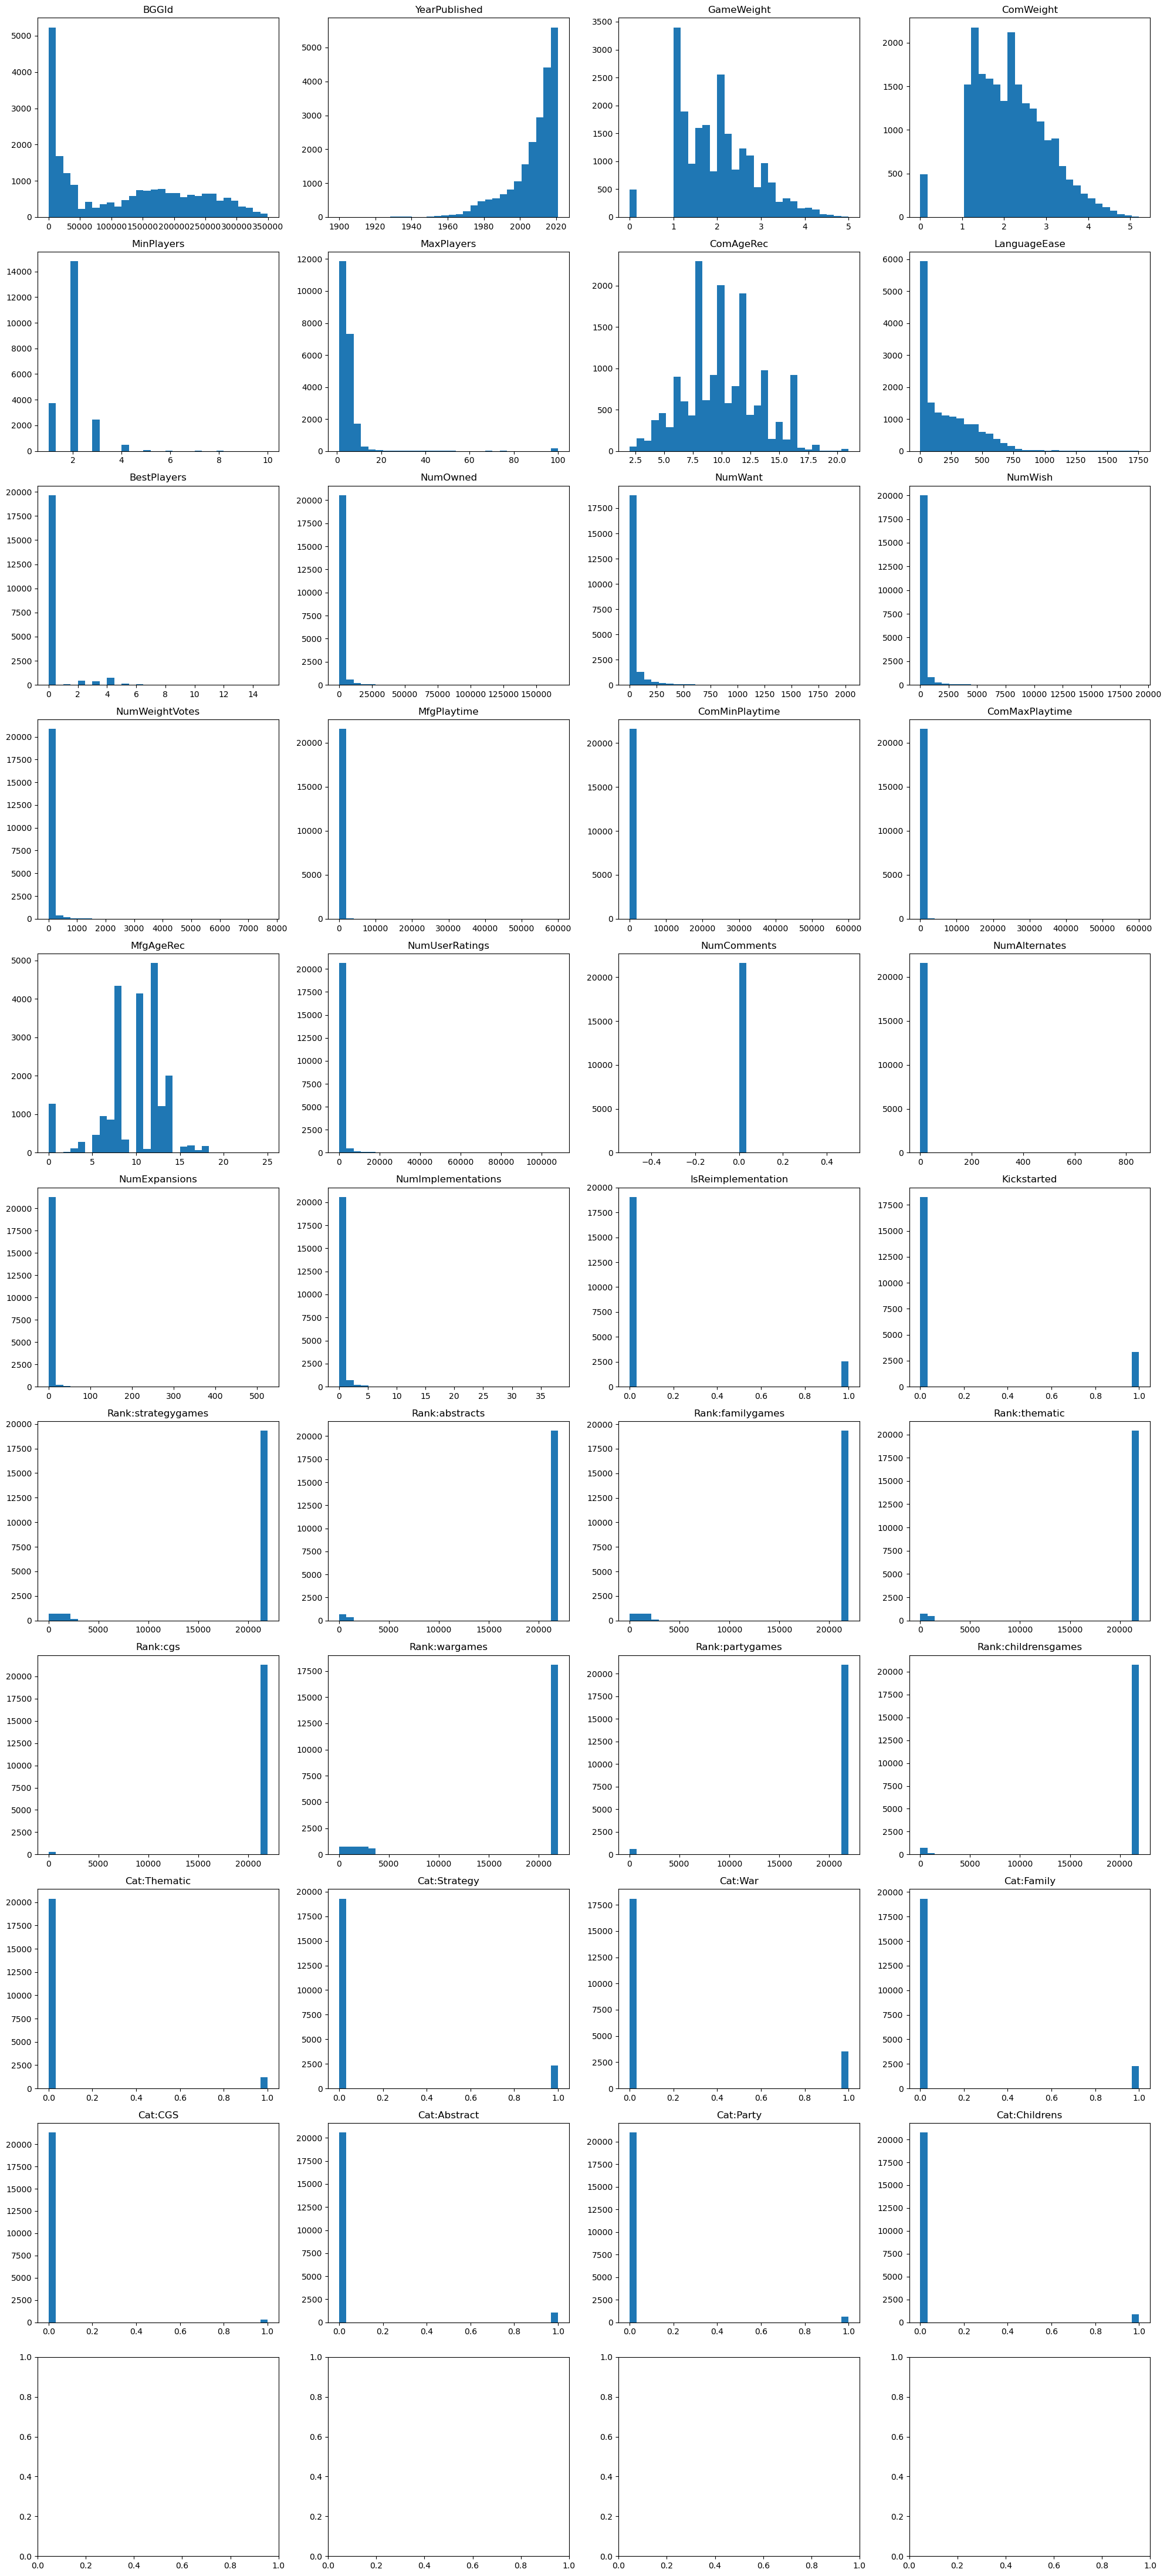

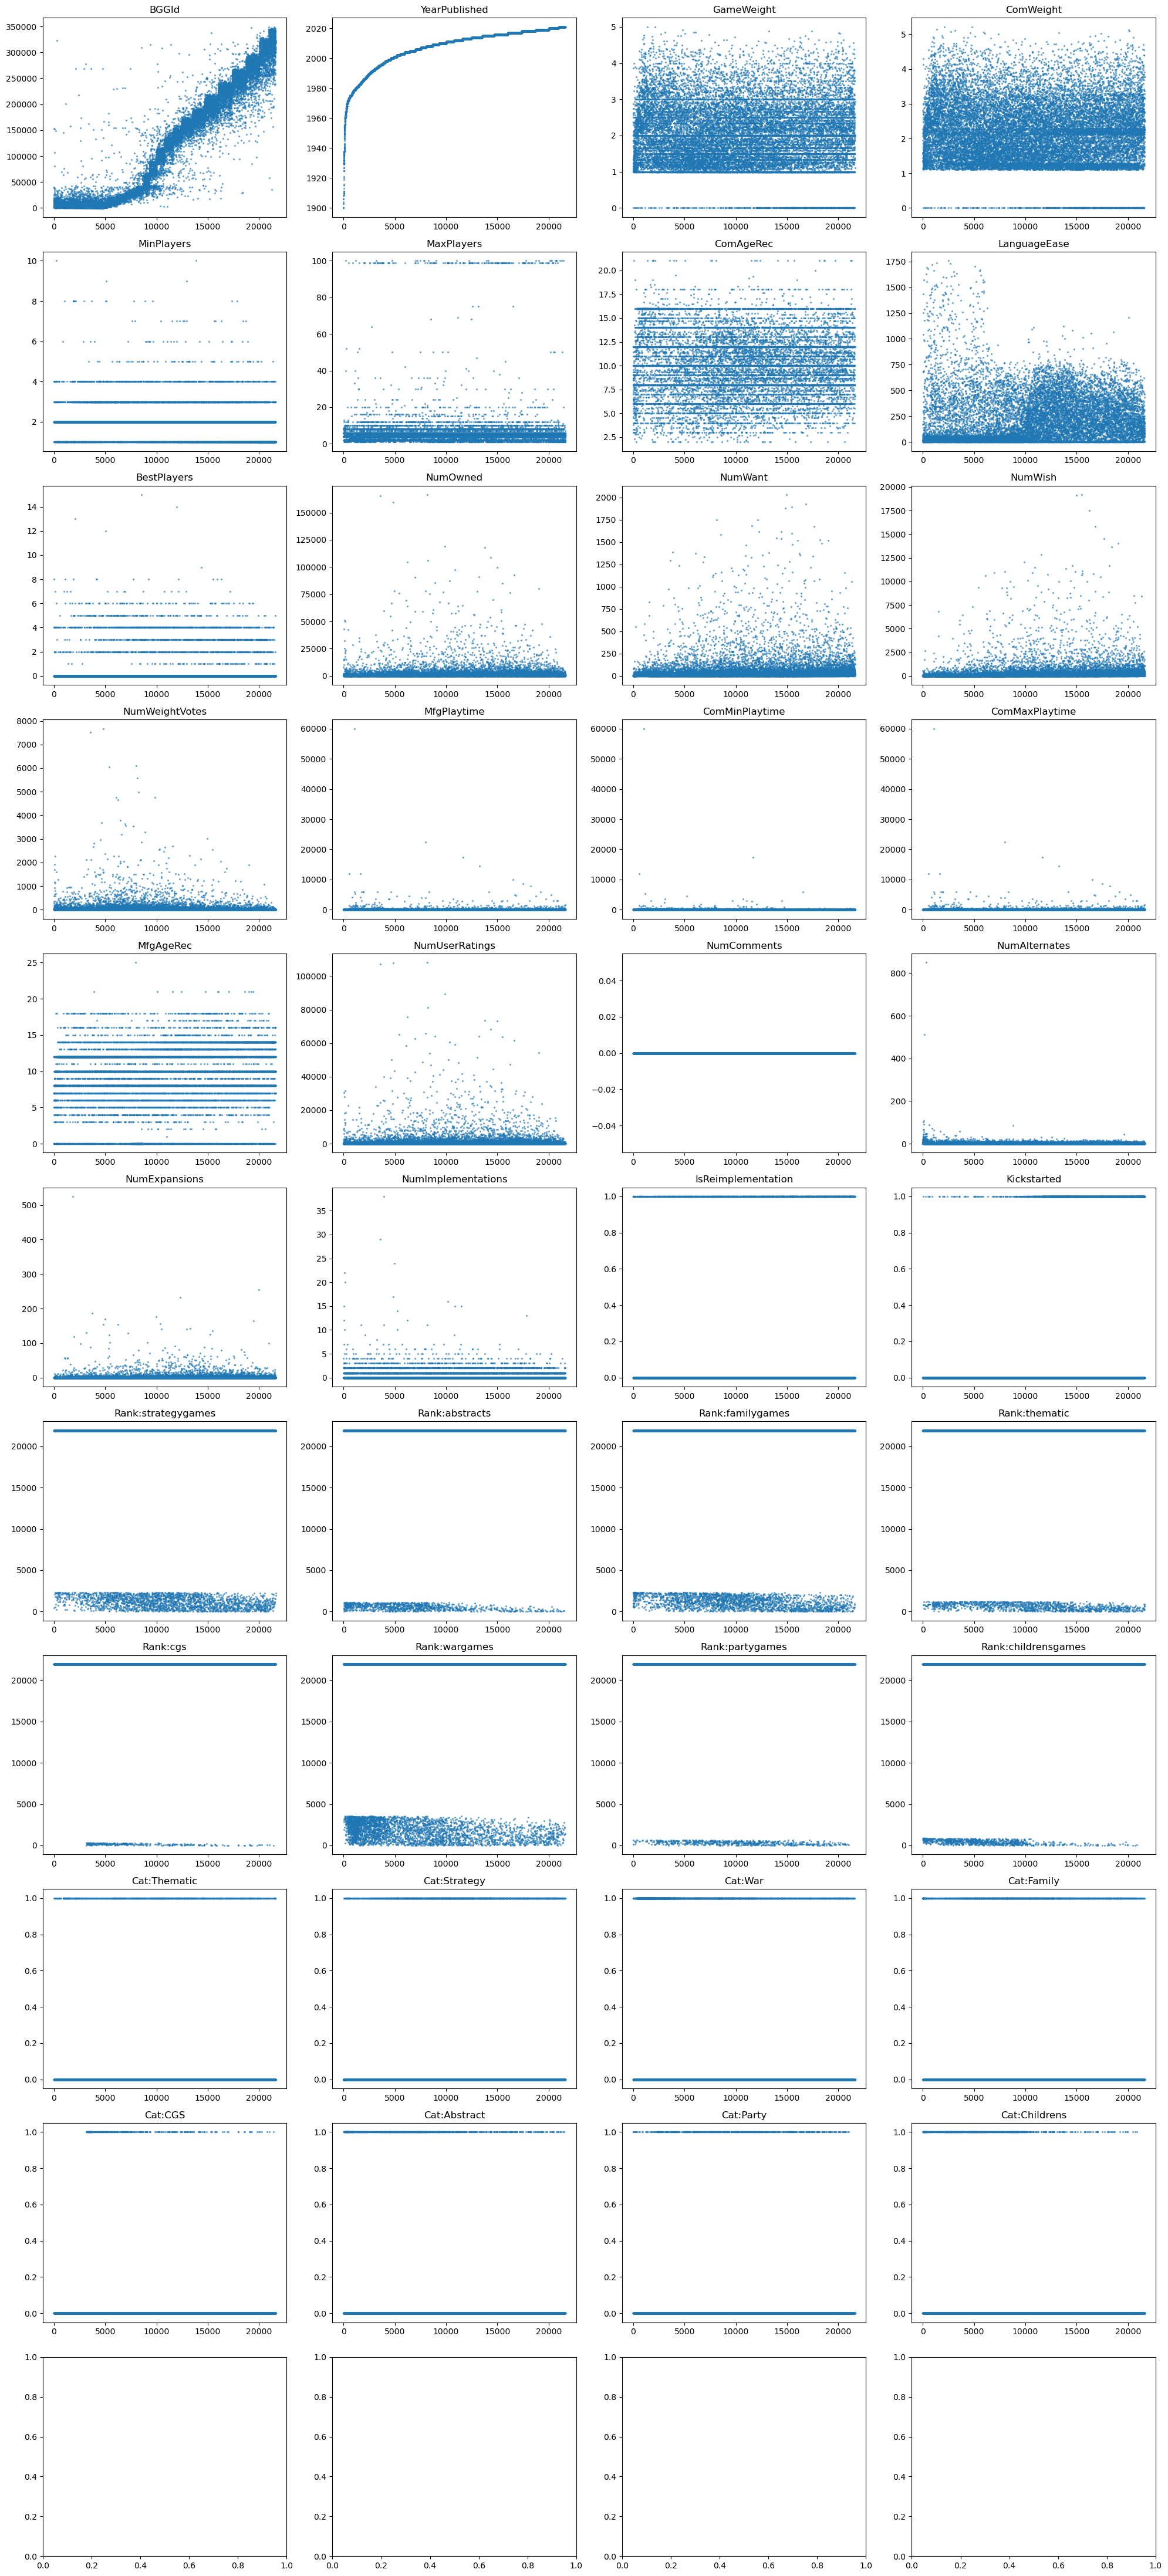

In [88]:
numeric_cols_all = df_clean.select_dtypes(include=[np.number]).columns

# Quick histograms
fig, axes = plt.subplots(len(numeric_cols_all)//4 + 1, 4, figsize=(20, 4 * (len(numeric_cols_all)//4 + 1)))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols_all):
    ax.hist(df_clean[col].dropna(), bins=30)
    ax.set_title(col)

plt.tight_layout()
plt.show()

# Scatterplots vs index: simple anomaly spotting
fig, axes = plt.subplots(len(numeric_cols_all)//4 + 1, 4, figsize=(20, 4 * (len(numeric_cols_all)//4 + 1)))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols_all):
    ax.scatter(range(len(df_clean)), df_clean[col], s=2, alpha=0.5)
    ax.set_title(col)

plt.tight_layout()
plt.show()

## Step 05: Playtime cleaning (cap insane values)
anything > 1800 minutes (~30 hours) is considered invalid/unusable and replaced by NaN

In [89]:
for col in ["ComMinPlaytime", "ComMaxPlaytime", "MfgPlaytime"]:
    if col in df_clean.columns:
        df_clean.loc[df_clean[col] > 1800, col] = np.nan

## Step 06: Missing Values Overview

In [90]:
missing = df_clean.isna().sum().sort_values(ascending=False)
missing[missing > 0]

Family            15011
LanguageEase       5802
ComAgeRec          5444
ComMaxPlaytime       57
MfgPlaytime          57
ImagePath            14
ComMinPlaytime       14
Description           1
dtype: int64

## Step 07: Model-based imputation for ComAgeRec

use MfgAgeRec to predict ComAgeRec with a model-based imputation (and use other variables to do this too):
<br>
 
We’ll use RandomForestRegressor with predictors:
- `MfgAgeRec` (obvious)
- plus complexity/players/popularity: `GameWeight`, `MinPlayers`, `MaxPlayers`, `YearPublished`

In [91]:
age_features = ["MfgAgeRec", "GameWeight", "MinPlayers", "MaxPlayers", "YearPublished"]

# 1. Training data: rows where ComAgeRec is known and predictors not missing
age_train = df_clean.dropna(subset=["ComAgeRec"] + age_features)
X_age = age_train[age_features]
y_age = age_train["ComAgeRec"]

# 2. Train model
X_train, X_valid, y_train, y_valid = train_test_split(X_age, y_age, test_size=0.2, random_state=42)
rf_age = RandomForestRegressor(random_state=42, n_estimators=200)
rf_age.fit(X_train, y_train)
print("R² on validation for ComAgeRec imputation:", r2_score(y_valid, rf_age.predict(X_valid)))

# 3. Predict missing
age_missing = df_clean[df_clean["ComAgeRec"].isna()]
if not age_missing.empty:
    df_clean.loc[age_missing.index, "ComAgeRec"] = rf_age.predict(age_missing[age_features])

R² on validation for ComAgeRec imputation: 0.6295537441429233


**`ComAgeRec` was imputed using a Random Forest model trained on `MfgAgeRec`, `GameWeight`, `MinPlayers`, `MaxPlayers`, and `YearPublished`. The model achieved an R² of 0.63 on a held-out validation set, indicating good predictive power and supporting model-based imputation rather than mean/median replacement.**

## Step 08: Model-based imputation for LanguageEase

Keep it and impute
<br>

We’ll predict LanguageEase using:
- `GameWeight` (complexity)
- `YearPublished`
- `MinPlayers`, `MaxPlayers`
- `NumOwned` (more popular games may report this more reliably)
- maybe `ComAgeRec` (just imputed)

In [92]:
lang_features = ["GameWeight", "YearPublished", "MinPlayers", "MaxPlayers",
                 "NumOwned", "ComAgeRec"]

lang_train = df_clean.dropna(subset=["LanguageEase"] + lang_features)
X_lang = lang_train[lang_features]
y_lang = lang_train["LanguageEase"]

X_train, X_valid, y_train, y_valid = train_test_split(X_lang, y_lang, test_size=0.2, random_state=42)
rf_lang = RandomForestRegressor(random_state=42, n_estimators=200)
rf_lang.fit(X_train, y_train)
print("R² on validation for LanguageEase imputation:", r2_score(y_valid, rf_lang.predict(X_valid)))

lang_missing = df_clean[df_clean["LanguageEase"].isna()]
if not lang_missing.empty:
    df_clean.loc[lang_missing.index, "LanguageEase"] = rf_lang.predict(lang_missing[lang_features])

R² on validation for LanguageEase imputation: 0.029324321067645598


**LanguageEase exhibited 27% missing values and model-based imputation using Random Forest achieved an R² of only 0.03, indicating negligible predictive power. Since the variable is subjective and uninformative for downstream modeling, it was removed.**

In [93]:
# Drop LanguageEase
df_clean = df_clean.drop(columns=["LanguageEase"])

## Step 09: Simple median imputation for remaining numeric NaNs
Numeric variables with less than 1% missing values (e.g., ComMinPlaytime and ComMaxPlaytime) were imputed using the median. Median imputation was selected because these variables exhibit highly skewed distributions, making it more robust than mean imputation. No model-based imputation was necessary due to the minimal missingness.

In [94]:
# Identify numeric columns
numeric_cols = df_clean.select_dtypes(include=["float64", "int64"]).columns

# Impute remaining missing numeric values with median
df_clean[numeric_cols] = df_clean[numeric_cols].fillna(df_clean[numeric_cols].median())

# Confirm no missing numeric values remain
print(df_clean[numeric_cols].isna().sum().sort_values())

BGGId                  0
IsReimplementation     0
Kickstarted            0
Rank:strategygames     0
Rank:abstracts         0
Rank:familygames       0
Rank:thematic          0
Rank:cgs               0
NumImplementations     0
Rank:wargames          0
Rank:childrensgames    0
Cat:Thematic           0
Cat:Strategy           0
Cat:War                0
Cat:Family             0
Cat:CGS                0
Cat:Abstract           0
Rank:partygames        0
Cat:Party              0
NumExpansions          0
NumComments            0
YearPublished          0
GameWeight             0
ComWeight              0
MinPlayers             0
MaxPlayers             0
ComAgeRec              0
BestPlayers            0
NumAlternates          0
NumOwned               0
NumWish                0
NumWeightVotes         0
MfgPlaytime            0
ComMinPlaytime         0
ComMaxPlaytime         0
MfgAgeRec              0
NumUserRatings         0
NumWant                0
Cat:Childrens          0
dtype: int64


## Step 10: Decide between NumOwned, NumWeightVotes, and GameWeight
We want to:
- Compute correlations between: `NumOwned`, `NumWeightVotes`, `GameWeight`
- Decide which to keep
- Provide reasoning

In [95]:
# Check correlation among popularity/complexity-related features
cols_check = ["NumOwned", "NumWeightVotes", "GameWeight"]
corr_subset = df_clean[cols_check].corr()

print(corr_subset)

# Also rank correlations by strength
abs_corr = corr_subset.abs().unstack().sort_values(ascending=False)
print("\nTop correlations:\n", abs_corr.head(10))

                NumOwned  NumWeightVotes  GameWeight
NumOwned        1.000000        0.874600    0.088221
NumWeightVotes  0.874600        1.000000    0.120096
GameWeight      0.088221        0.120096    1.000000

Top correlations:
 NumOwned        NumOwned          1.000000
NumWeightVotes  NumWeightVotes    1.000000
GameWeight      GameWeight        1.000000
NumOwned        NumWeightVotes    0.874600
NumWeightVotes  NumOwned          0.874600
                GameWeight        0.120096
GameWeight      NumWeightVotes    0.120096
NumOwned        GameWeight        0.088221
GameWeight      NumOwned          0.088221
dtype: float64


**`NumOwned` and `NumWeightVotes` are highly correlated, meaning both measure user engagement. Since `NumOwned` is easier to interpret and has fewer zeros, we retained `NumOwned` and removed `NumWeightVotes` to reduce redundancy. `GameWeight` was kept because it captures gameplay complexity rather than popularity (important for clustering and modeling).**

In [96]:
df_clean = df_clean.drop(columns=["NumWeightVotes"])

## Step 11: merge NumWish + NumWant into NumInterest

In [97]:
# Create combined interest metric
df_clean["NumInterest"] = df_clean["NumWish"] + df_clean["NumWant"]

# Drop original columns if desired
df_clean = df_clean.drop(columns=["NumWish", "NumWant"])

# Verify
print(df_clean[["NumInterest"]].head())

     NumInterest
309            2
310           10
311            1
312           22
313          623


**Since `NumWish` and `NumWant` capture similar user intent signals, they were combined into a single feature (`NumInterest`) to reduce dimensionality and avoid redundancy.**

## Step 12: Log-transform the remaining skewed count features
log1p because count features are:
- extremely right-skewed
- contain zeros so log1p avoids log(0)
- improves clustering + distance-based algorithms

In [98]:
import numpy as np

# Count-based features that remain after cleanup
count_cols_to_log = [
    "NumOwned",
    "NumUserRatings",
    "NumAlternates",
    "NumExpansions",
    "NumImplementations",
    "NumInterest"   # merged feature
]

# Apply log1p transformation
for col in count_cols_to_log:
    df_clean[col + "_log"] = np.log1p(df_clean[col])

# Quick confirmation
df_clean[[c for c in df_clean.columns if c.endswith("_log")]].head()

,NumOwned_log,NumUserRatings_log,NumAlternates_log,NumExpansions_log,NumImplementations_log,NumInterest_log
309,4.983607,3.713572,2.944439,0.000000,1.098612,1.098612
310,3.258097,3.637586,0.000000,0.000000,0.000000,2.397895
311,3.044522,3.526361,2.302585,0.000000,0.000000,0.693147
312,7.522400,6.073045,1.098612,0.000000,0.000000,3.135494
313,9.623509,9.053920,2.995732,0.693147,0.693147,6.436150


**Log1p transformation was applied to highly skewed count variables to reduce skewness and stabilize variance prior to distance-based clustering.**

## Step 13: Removing Agreed-Upon Columns

In [104]:
cols_to_drop = [
    "ComWeight",
    "BestPlayers",
    "NumComments",
    "MfgPlaytime",
    "Family",
    "GoodPlayers",
    "ImagePath",
    "Name",
    "Description",
    "LanguageEase" # refer to step 08 to understand why it's been removed
    
    # all rank columns
    "Rank:strategygames",
    "Rank:abstracts",
    "Rank:familygames",
    "Rank:thematic",
    "Rank:cgs",
    "Rank:wargames",
    "Rank:partygames",
    "Rank:childrensgames",
    "Rank:strategygames"

]

df_clean = df_prepared.drop(
    columns=[c for c in cols_to_drop if c in df_prepared.columns]
)

## Step 13: Correlation matrix

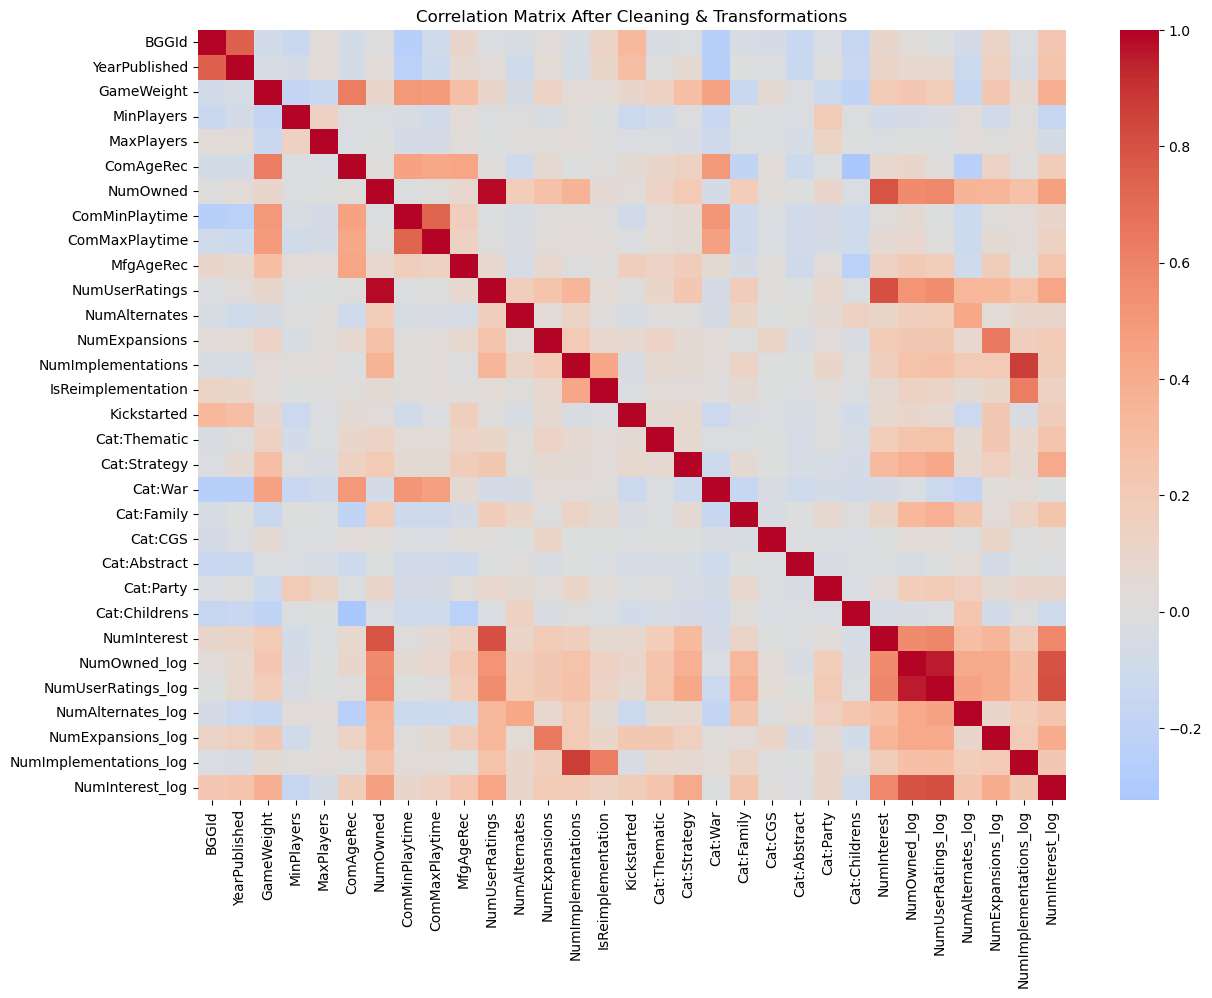

In [105]:
import seaborn as sns
import matplotlib.pyplot as plt

# Numeric columns only
numeric_cols = df_clean.select_dtypes(include=["float64", "int64"]).columns

corr_matrix = df_clean[numeric_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0)
plt.title("Correlation Matrix After Cleaning & Transformations")
plt.show()

## Step 14: Final Cleaned Dataset

In [106]:
df_prepared = df_clean.copy()

print("\n Final Prepared Dataset:")
df_prepared.info()
print("\nShape:", df_prepared.shape)


 Final Prepared Dataset:
<class 'pandas.core.frame.DataFrame'>
Index: 21616 entries, 309 to 21924
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   BGGId                   21616 non-null  int64  
 1   YearPublished           21616 non-null  int64  
 2   GameWeight              21616 non-null  float64
 3   MinPlayers              21616 non-null  int64  
 4   MaxPlayers              21616 non-null  int64  
 5   ComAgeRec               21616 non-null  float64
 6   NumOwned                21616 non-null  int64  
 7   ComMinPlaytime          21616 non-null  float64
 8   ComMaxPlaytime          21616 non-null  float64
 9   MfgAgeRec               21616 non-null  int64  
 10  NumUserRatings          21616 non-null  int64  
 11  NumAlternates           21616 non-null  int64  
 12  NumExpansions           21616 non-null  int64  
 13  NumImplementations      21616 non-null  int64  
 14  IsReimplementat

In [108]:
df_prepared.to_csv("df_prepared.csv", index=False)
print("Saved ✅ df_prepared.csv")

Saved ✅ df_prepared.csv
